# Explainable Predictive Maintenance (Decision Tree Replication)
This notebook replicates the explainable model approach from the paper *"Explainable Artificial Intelligence for Predictive Maintenance Applications"* by Stephan Matzka (2020).

In [106]:
import sys
print(sys.executable)

/Library/Frameworks/Python.framework/Versions/3.12/bin/python3


In [107]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [108]:
from Scripts.RandomForestTrain import trainRF
from Scripts.DecisionTreeTrain import train_explainable_tree, evaluate_tree, plot_decision_tree

In [109]:
model, X_test, y_test, y_pred_rf, y_proba_rf, results = trainRF("configs/RandomForest/RFtrain.yaml")

# Train Explainable Decision Tree using RF
dt, top_features, y_pred_dt = train_explainable_tree(
    rf, X_train, X_test, y_train, y_test
)

Top Features from RF: ['Torque [Nm]', 'Rotational speed [rpm]', 'Tool wear [min]', 'Air temperature [K]']


/Users/martinwalterampah/Library/Python/3.12/lib/python/site-packages/sklearn/calibration.py:330: FutureWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


In [110]:
print("Chosen threshold:", results["threshold"])
print("PR-AUC:", results["pr_auc"])
print("ROC-AUC:", results["roc_auc"])

Chosen threshold: 0.2469387755102041
PR-AUC: 0.715609070185756
ROC-AUC: 0.9576939471440751


In [111]:
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

In [112]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, digits=4))

print("\nROC AUC:", roc_auc_score(y_test, y_proba_rf))
print("Average Precision (PR AUC):", average_precision_score(y_test, y_proba_rf))

print("\nChosen Threshold:", results["threshold"])

Confusion Matrix:
[[1929    3]
 [  32   36]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9837    0.9984    0.9910      1932
           1     0.9231    0.5294    0.6729        68

    accuracy                         0.9825      2000
   macro avg     0.9534    0.7639    0.8320      2000
weighted avg     0.9816    0.9825    0.9802      2000


ROC AUC: 0.9697014675435393
Average Precision (PR AUC): 0.8065633773182322

Chosen Threshold: 0.2469387755102041


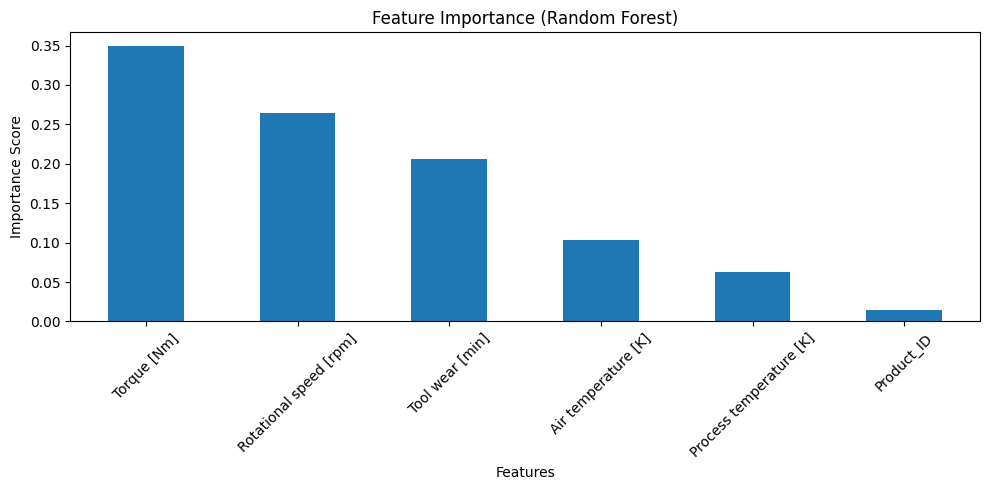

In [113]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importances
importances = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

# Plot
plt.figure(figsize=(10, 5))
importances.plot(kind='bar')

plt.title('Feature Importance (Random Forest)')
plt.ylabel('Importance Score')
plt.xlabel('Features')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [97]:
# =========================================================
# Create timestamped experiment folder + save artifacts
# =========================================================

import os
import yaml
import joblib
from datetime import datetime
import json

# --- 1. Create timestamp ---
timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# --- 2. Define base experiment directory ---
base_dir = "experiments_rf"
run_dir = os.path.join(base_dir, f"run_{timestamp}")

# --- 3. Create directory ---
os.makedirs(run_dir, exist_ok=True)

print(f"Experiment directory created: {run_dir}")

# --- 4. Save trained model ---
model_path = os.path.join(run_dir, "random_forest.pkl")
joblib.dump(rf, model_path)

print(f"Model saved to: {model_path}")

# --- 5. Save config file ---
config_src = "configs/RandomForest/RFtrain.yaml"
config_dst = os.path.join(run_dir, "RFtrain.yaml")

with open(config_src, "r") as f:
    config_data = yaml.safe_load(f)

with open(config_dst, "w") as f:
    yaml.dump(config_data, f)

print(f"Config saved to: {config_dst}")

# --- 6. (Optional) Save metrics ---
from sklearn.metrics import confusion_matrix, classification_report

metrics = {
    "confusion_matrix": confusion_matrix(y_test, y_pred_rf).tolist(),
    "classification_report": classification_report(y_test, y_pred_rf, output_dict=True)
}

metrics_path = os.path.join(run_dir, "metrics.json")

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

print(f"Metrics saved to: {metrics_path}")


notes_path = os.path.join(run_dir, "notes.txt")

with open(notes_path, "w") as f:
    f.write(
        "Experiment Notes\n"
        "=================\n\n"
        f"Timestamp: {timestamp}\n\n"
        "Observations:\n- \n\n"
        "Changes Made:\n- \n\n"
        "Next Steps:\n- \n"
    )
    print(f"Notes file created at: {notes_path}")

Experiment directory created: experiments_rf/run_2026-04-21_13-57-39
Model saved to: experiments_rf/run_2026-04-21_13-57-39/random_forest.pkl
Config saved to: experiments_rf/run_2026-04-21_13-57-39/RFtrain.yaml
Metrics saved to: experiments_rf/run_2026-04-21_13-57-39/metrics.json
Notes file created at: experiments_rf/run_2026-04-21_13-57-39/notes.txt


### RF (learns complex patterns) → guides → DT (explains those patterns)


--- Simple Decision Tree Classifier ---
[[1586  346]
 [   6   62]]
              precision    recall  f1-score   support

           0     0.9962    0.8209    0.9001      1932
           1     0.1520    0.9118    0.2605        68

    accuracy                         0.8240      2000
   macro avg     0.5741    0.8663    0.5803      2000
weighted avg     0.9675    0.8240    0.8784      2000



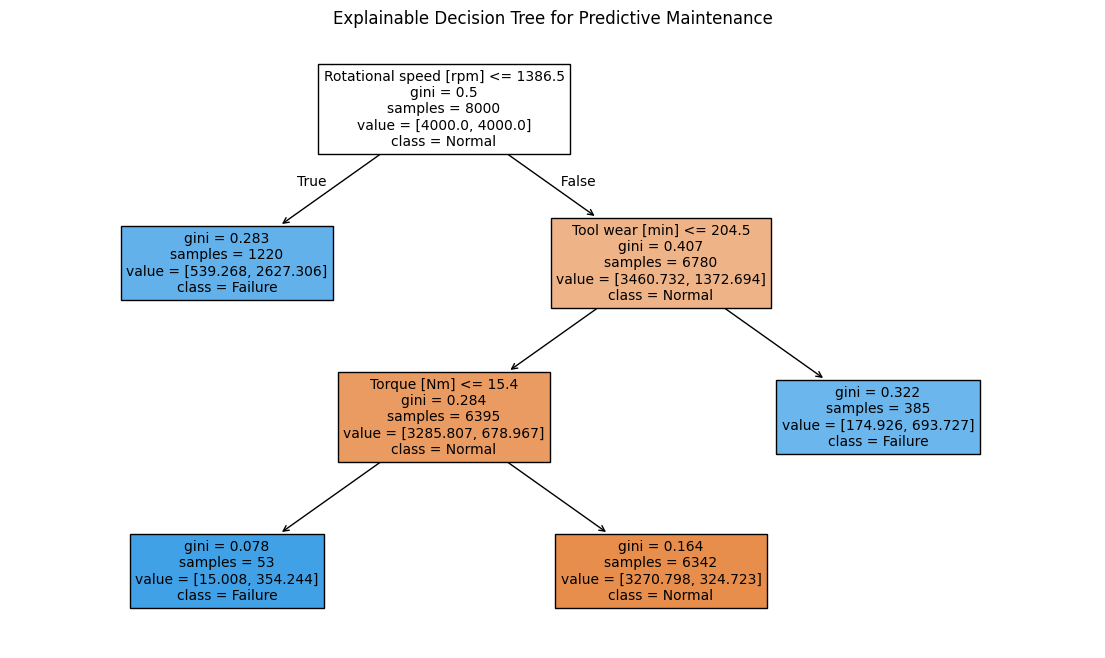

In [70]:
evaluate_tree(y_test, y_pred_dt)
plot_decision_tree(dt, top_features)

### It acts as the bridge:

##### RF = What matters globally
##### DT = How to explain it locally

In [34]:
X_test_subset = X_test[top_features]
print("Trained on:", dt.feature_names_in_)
print("Predicting on:", X_test_subset.columns.tolist())

Trained on: ['Torque [Nm]' 'Rotational speed [rpm]' 'Tool wear [min]'
 'Air temperature [K]']
Predicting on: ['Torque [Nm]', 'Rotational speed [rpm]', 'Tool wear [min]', 'Air temperature [K]']


In [36]:
from sklearn.tree import export_text
# ===========================================================
# 3. INTERPRETATION
# ===========================================================
rules = export_text(dt, feature_names=list(top_features))
print('\nDecision Tree Rules:\n')
print(rules)


Decision Tree Rules:

|--- Rotational speed [rpm] <= 1386.50
|   |--- class: 1
|--- Rotational speed [rpm] >  1386.50
|   |--- Tool wear [min] <= 204.50
|   |   |--- Torque [Nm] <= 15.40
|   |   |   |--- class: 1
|   |   |--- Torque [Nm] >  15.40
|   |   |   |--- class: 0
|   |--- Tool wear [min] >  204.50
|   |   |--- class: 1



In [38]:
#===========================================================
#4. Example Local Explanation (Normalized Feature Deviation)
#===========================================================
sample = X_test.iloc[10][top_features]

# Using training stats
normed = (sample - X_train[top_features].mean()) / X_train[top_features].std()
print('\nNormalized Feature Deviation for a Single Data Point:')
print(normed.abs().sort_values(ascending=False))
print('\nPredicted Class:', 'Failure' if dt.predict([sample])[0] == 1 else 'Normal')


Normalized Feature Deviation for a Single Data Point:
Air temperature [K]       0.503520
Rotational speed [rpm]    0.263246
Tool wear [min]           0.256477
Torque [Nm]               0.140062
dtype: float64

Predicted Class: Normal


/Users/martinwalterampah/Library/Python/3.12/lib/python/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [41]:
import pandas as pd
import yaml

# Load config
with open("configs/RandomForest/train.yaml", "r") as f:
    cfg = yaml.safe_load(f)

# Load full dataset
df = pd.read_csv(cfg["data"]["path"])

# Recreate preprocessing
df["Product_ID"] = df["Product ID"].str[0]
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
df["Product_ID"] = encoder.fit_transform(df["Product_ID"])

X = df[cfg["features"]["input"]]
y = df[cfg["features"]["target"]]

In [42]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
#===========================================================
#5. Cross-validation Evaluation
#===========================================================
scores = cross_val_score(dt, X[top_features], y, cv=5)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1_scores = cross_val_score(dt, X[top_features], y, cv=cv, scoring='f1')
recall_scores = cross_val_score(dt, X[top_features], y, cv=cv, scoring='recall')

print('\nDecision Tree Cross-Validation Accuracy: {:.2f}% ± {:.2f}'.format(scores.mean()*100, scores.std()*100))
print('\nDecision Tree Cross-Validation f1_scores: {:.2f}% ± {:.2f}'.format(f1_scores.mean()*100, f1_scores.std()*100))
print('\nDecision Tree Cross-Validation recall_scores: {:.2f}% ± {:.2f}'.format(recall_scores.mean()*100, recall_scores.std()*100)) 


Decision Tree Cross-Validation Accuracy: 81.48% ± 1.02

Decision Tree Cross-Validation f1_scores: 25.40% ± 0.89

Decision Tree Cross-Validation recall_scores: 91.46% ± 2.51
